##### <center>Beyond global density in a stochastic sandpile: the role of spatial signatures in the predictability of extremes</center>
<center>K.P. Orzechowski, J. Sienkiewicz & P. Fronczak</center> <br>
<center>Workbook 2: Shapoval</center>

---

The collected data and the baseline, that is prediction from density alone on the full stream. The baseline cell reads the full streams (500 million steps per phase) and needs about 15 GB of memory.

---

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, "../data_management")
import M2_Shapoval as m

pd.set_option("display.max_columns", None)
SIZES = (32, 64, 128)

COLORS = {32: "darkgoldenrod", 64: "darkred", 128: "darkgreen"}
MARKERS = {32: "^", 64: "o", 128: "s"}
DASHES = {32: "-.", 64: "-", 128: "--"}
BG, TEXT, LABEL, GRAY, AXIS = "#ffffff", "#0b0b0b", "#52514e", "#898781", "#c3c2b7"
plt.rcParams["pdf.fonttype"] = 42

#### Collected examples (Table 1)

In [2]:
data = {L: m.collected_examples(L) for L in SIZES}
m.table(data)

,train_pool.n,train_pool.pos,train_pool.neg,train_pool.q_pos,train_pool.q_neg,test_pool.n,test_pool.pos,test_pool.neg,test_pool.q_pos,test_pool.q_neg
32,18114,8114,10000,0.711721,0.687658,18108,8108,10000,0.711429,0.687639
64,12674,2674,10000,0.711210,0.699791,12741,2741,10000,0.711254,0.699883
128,11339,1339,10000,0.712373,0.707261,11309,1309,10000,0.712451,0.707258


#### Number of extremes when the system size is doubled (Section 2.1)

In [3]:
extremes = pd.Series({L: data[L]["train_pool"]["pos"] + data[L]["test_pool"]["pos"] for L in SIZES})
pd.DataFrame({"extremes in both phases": extremes, "ratio to the smaller system": extremes / extremes.shift(),
              "ratio from scaling": 2 ** (-m.D_AVALANCHE * (m.BETA_AVALANCHE - 1))})

,extremes in both phases,ratio to the smaller system,ratio from scaling
32,16222,NaN,0.594604
64,5415,0.333806,0.594604
128,2648,0.489012,0.594604


#### Consistency of the collected examples with the stream

In [4]:
collector = {L: m.collector_vs_stream(L) for L in SIZES}
m.table({(L, pool): w for L in SIZES for pool, w in collector[L].items()})

extremes_in_stream  labels_consistent negatives_spacing  \
32  train_pool                8114               True    [50000, 50000]   
    test_pool                 8108               True    [50000, 50001]   
64  train_pool                2674               True    [50000, 50000]   
    test_pool                 2741               True    [50000, 50000]   
128 train_pool                1339               True    [50000, 50000]   
    test_pool                 1309               True    [50000, 50000]   

                    ks_D      ks_p  
32  train_pool  0.003410  0.999878  
    test_pool   0.006250  0.848504  
64  train_pool  0.005865  0.896647  
    test_pool   0.009600  0.341712  
128 train_pool  0.007385  0.673680  
    test_pool   0.006615  0.796240

#### Independence of the examples (Section 2.7)

In [5]:
independence = {L: {pool: m.example_independence(pool, L) for pool in ("train_pool", "test_pool")} for L in SIZES}
m.table({(L, pool): w for L in SIZES for pool, w in independence[L].items()})

cv_extreme_gaps                  autocorrelation_q_negatives
32  train_pool         0.992088    [-0.01467, -0.01194, 0.0009802, -0.01495]
    test_pool          0.988892    [-0.009543, 0.01198, -0.01719, -0.005003]
64  train_pool         0.983611      [-0.01256, -0.009659, -0.00986, 0.0121]
    test_pool          0.978985   [-0.01078, 0.0005618, 0.01102, -0.0003863]
128 train_pool         1.046093  [0.006363, -0.007172, -0.009281, -0.002022]
    test_pool          1.013660    [-0.0005752, -0.0182, 0.009418, 0.008835]

#### Prediction from density alone on the full stream (Table 3)

In [6]:
baseline = {L: m.baseline(L) for L in SIZES}
m.table(baseline, skip=("roc", "pdf"))

,T,auc,alpha,delta1,q_star,eps_qt,eps_threshold
32,500000000,0.954177,1.329894,2.071316,0.700195,0.228172,0.228172
64,500000000,0.967427,1.297601,2.190480,0.705811,0.191600,0.194718
128,500000000,0.972510,1.293275,2.222022,0.709900,0.171864,0.174257


#### Comparison with Shapoval et al. (2022), L = 128

In [7]:
m.table(m.comparison_with_shapoval(baseline[128], data[128]["test_pool"]["pos"]))

,ours,shapoval,difference_in_standard_errors
AUC,0.972510,0.9460,1.925467
q*,0.709900,0.7098,NaN
eps,0.174257,0.2050,1.327841
delta_1,2.222022,2.2300,NaN
extremes per 10^7 steps,26.180000,26.2000,NaN


#### Collapse of the rescaled avalanche distributions

In [8]:
collapse = m.distribution_collapse({L: baseline[L]["pdf"] for L in SIZES})
pd.Series(collapse, name="mean |difference of log10 density|")

32-64     0.027050
32-128    0.040724
64-128    0.023311
Name: mean |difference of log10 density|, dtype: float64

#### Figure 1

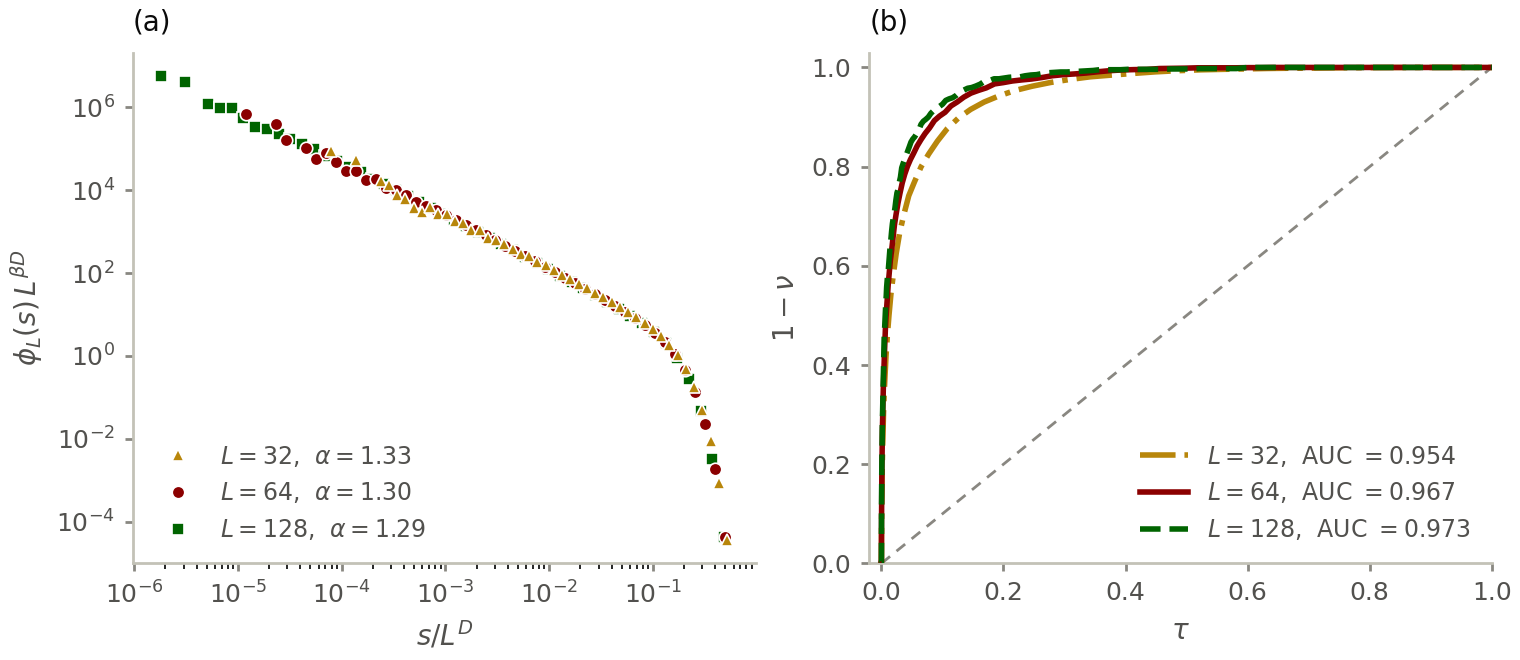

In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.6, 3.3), dpi=200, layout="constrained", facecolor=BG)
for i, L in enumerate(SIZES):
    s, density = np.array(baseline[L]["pdf"])
    false_alarms, detected = baseline[L]["roc"]
    a1.plot(s / L**m.D_AVALANCHE, density * L**(m.BETA_AVALANCHE * m.D_AVALANCHE), linestyle="", marker=MARKERS[L], markersize=4.5, color=COLORS[L],
            markeredgecolor=BG, markeredgewidth=0.6, zorder=6 - i, label=f"$L={L}$,  $\\alpha={baseline[L]['alpha']:.2f}$")
    a2.plot(false_alarms, detected, color=COLORS[L], linewidth=2.0, linestyle=DASHES[L], zorder=3, label=f"$L={L}$,  AUC $={baseline[L]['auc']:.3f}$")
a2.plot([0, 1], [0, 1], color=GRAY, linewidth=1.0, linestyle=(0, (4, 3)), zorder=1)

a1.set_xscale("log")
a1.set_yscale("log")
a1.set_xlabel("$s/L^{D}$", fontsize=10, color=LABEL)
a1.set_ylabel(r"$\phi_L(s)\,L^{\beta D}$", fontsize=10, color=LABEL)
a1.set_title("(a)", fontsize=10, color=TEXT, loc="left", pad=8)
a1.legend(frameon=False, fontsize=8.5, labelcolor=LABEL, loc="lower left")

a2.set_xlim(-0.02, 1.0)
a2.set_ylim(0, 1.03)
a2.set_xlabel(r"$\tau$", fontsize=10, color=LABEL)
a2.set_ylabel(r"$1-\nu$", fontsize=10, color=LABEL)
a2.set_title("(b)", fontsize=10, color=TEXT, loc="left", pad=8)
a2.legend(frameon=False, fontsize=8.5, labelcolor=LABEL, loc="lower right")
a2.xaxis.set_major_formatter("{x:.1f}")
a2.yaxis.set_major_formatter("{x:.1f}")

for ax in (a1, a2):
    ax.set_facecolor(BG)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["bottom", "left"]].set(color=AXIS, linewidth=1.0)
    ax.tick_params(color=GRAY, labelcolor=LABEL, labelsize=9, length=3, width=1.0)

fig.savefig("../data_repository/figures/fig_shapoval.png")
fig.savefig("../data_repository/figures/fig_shapoval.pdf")
plt.close(fig)
display(Image("../data_repository/figures/fig_shapoval.png"))